# Behind GoEmotions: model training and hyperparameter tuning

This notebook is dedicated to the **modeling and experimentation** phase. The main objective is to train and compare four different architectures for the emotion classification task, starting from classical baselines up to complex deep learning and contextual models.

Each model is optimized using **keras tuner** to identify the most robust hyperparameter configuration, monitoring loss and accuracy metrics on the validation set to prevent overfitting and shortcut learning.

## Notebook objectives

1. **Baseline definition**: configure traditional models to establish an accuracy and computational benchmark.
2. **Architecture exploration**: implement and compare approaches based on word frequencies (TF-IDF), recurrent networks (BiLSTM) and attention mechanisms (transformer from scratch).
3. **Automated hyperparameter tuning**: use keras tuner to optimize hyperparameters.
4. **Tracking and reproducibility**: save weights, architectures, and learning curves of each experiment in their respective dedicated directories.

## Experimented models

The experimentation follows a path of increasing complexity, divided into two macro-approaches:

### 1. Frequency-based approaches
- **Logistic regression with TF-IDF**: allows evaluating the predictive power of key tokens without considering text order.
- **Multi-layer perceptron (MLP) with TF-IDF**: a dense neural network to capture non-linear interactions between features extracted by TF-IDF.

### 2. Sequential and attentional approaches
- **BiLSTM (bidirectional long short-term memory)**: recurrent neural network that processes text in both directions (left-to-right and right-to-left) to capture sequential dependencies and local context.
- **Transformer from scratch (encoder only)**: custom implementation of the encoder architecture based on self-attention mechanisms, to analyze long-range relationships between tokens in a parallel way.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_ROOT = '/content/drive/MyDrive/Behind_GoEmotions'

import os
os.chdir(PROJECT_ROOT)

print("current working directory:", os.getcwd())

Mounted at /content/drive
current working directory: /content/drive/MyDrive/Behind_GoEmotions


In [ ]:
# libraries import
import sys

import numpy as np
import pandas as pd
import json

import matplotlib.pyplot as plt
import seaborn as sns

import random
from datetime import date as date_cls

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import keras_tuner as kt

from sklearn.metrics import f1_score, accuracy_score, precision_recall_fscore_support

In [ ]:
# path definition
DATA_PATH = PROJECT_ROOT + '/data/processed'
VECTORIZED_PATH = DATA_PATH + '/vectorized'
EXPERIMENTS_PATH = PROJECT_ROOT + '/experiments'
RESULTS_PATH = PROJECT_ROOT + '/results'
EDA_PATH = RESULTS_PATH + '/eda'
COMPARISON_PATH = RESULTS_PATH + '/comparison'
TUNER_PATH = PROJECT_ROOT + '/tuner_results'

# per-model experiment paths (each with checkpoints/ logs/ figures/)
LINEAR_PATH = EXPERIMENTS_PATH + '/tfidf_linear'
MLP_PATH = EXPERIMENTS_PATH + '/tfidf_mlp'
BILSTM_PATH = EXPERIMENTS_PATH + '/bilstm'
TRANSFORMER_PATH = EXPERIMENTS_PATH + '/transformer'

# create all required directories (safe: exist_ok=True)
for base in [LINEAR_PATH, MLP_PATH, BILSTM_PATH, TRANSFORMER_PATH]:
    for sub in ['checkpoints', 'logs', 'figures']:
        os.makedirs(os.path.join(base, sub), exist_ok=True)

os.makedirs(VECTORIZED_PATH, exist_ok=True)
os.makedirs(EDA_PATH, exist_ok=True)
os.makedirs(COMPARISON_PATH, exist_ok=True)
os.makedirs(TUNER_PATH, exist_ok=True)

In [ ]:
SEED = 42

# environment variables for reproducibility
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["TF_CUDNN_DETERMINISTIC"] = "1"

def set_reproducibility(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)
    tf.config.experimental.enable_op_determinism()

set_reproducibility()

In [ ]:
# set constants
VOCAB_SIZE = 2500        # vocabulary size
SEQ_LEN = 128            # max sequence length
LR = 0.001               # learning rate
EMBEDDING_DIM = 128      # embedding dimension
BATCH_SIZE = 128         # batch size
EPOCHS = 20              # number of epochs
date = date_cls.today()  # execution date

## Dataset import
We load the dataset saved in the project folder.

In [ ]:
# load data from csv
df_train = pd.read_csv(os.path.join(DATA_PATH, 'df_train.csv'))
df_val = pd.read_csv(os.path.join(DATA_PATH, 'df_val.csv'))
df_test = pd.read_csv(os.path.join(DATA_PATH, 'df_test.csv'))

In [ ]:
# handle any NAs
X_train = df_train["processed_text"].fillna('').astype(str).values
X_val = df_val["processed_text"].fillna('').astype(str).values
X_test = df_test["processed_text"].fillna('').astype(str).values

In [ ]:
# target definition for each split
y_train = df_train["label_id"]
y_val = df_val["label_id"]
y_test = df_test["label_id"]

In [ ]:
# encode labels with id
label_names = np.sort(df_train["label"].unique())
NUM_CLASSES = len(label_names)
id_to_label = {i: label_names[i] for i in range(len(label_names))}

## Functions to compute and save metrics

### `compute_validation_metrics`

Calculates global classification metrics by transforming probabilities into point predictions using `argmax`. returns a dictionary with **accuracy**, **micro-f1** (global), and **macro-f1** (unweighted average across classes), useful for evaluating model performance in the presence of imbalance.

### `save_history_plot`

Automates training tracking. Saves epoch logs (train and validation loss and accuracy) in a `.csv` file and generates a two-panel chart with **loss** and **accuracy** curves, saving it as an image to visually analyze overfitting or convergence.

### `evaluate_and_save`

Coordinates the entire evaluation phase of a model on the validation set. Calculates global metrics by calling `compute_validation_metrics` and inserts them into a comprehensive `all_metrics` registry exported as csv. Furthermore, it calculates and saves in a separate report the **disaggregated metrics for each class** (precision, recall, f1-score, and support), allowing to identify on which specific emotions the model struggles the most.

In [ ]:
all_metrics = []

def compute_validation_metrics(y_true, y_prob):
    """returns accuracy, micro f1 and macro f1 for classification."""
    y_pred = np.argmax(y_prob, axis=1)
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'micro_f1': f1_score(y_true, y_pred, average='micro', zero_division=0),
        'macro_f1': f1_score(y_true, y_pred, average='macro', zero_division=0),
    }


def save_history_plot(history, model_name, path):
    """saves training history as .csv and generates optimized loss and accuracy plots."""
    history_df = pd.DataFrame(history.history)
    history_df.to_csv(os.path.join(path, 'logs', f'history_{date}_{model_name}.csv'), index=False)

    # set a clean and modern style
    plt.style.use('seaborn-v0_8-whitegrid')

    # create figure proportions
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True)

    # stylized main title
    fig.suptitle(f"training history {model_name}", fontsize=15, fontweight='bold', y=0.98, color='#2c3e50')

    # custom color palette (deep blue and coral/orange)
    c_train = '#1f77b4'
    c_val = '#e74c3c'

    epochs = range(1, len(history_df) + 1)

    # plot loss
    axes[0].plot(epochs, history_df['loss'], label='train', color=c_train, linewidth=2, marker='o', markersize=4)
    axes[0].plot(epochs, history_df['val_loss'], label='validation', color=c_val, linewidth=2, linestyle='--', marker='s', markersize=4)
    axes[0].set_title('loss convergence', fontsize=12, fontweight='semibold', pad=10)
    axes[0].set_ylabel('sparse categorical crossentropy', fontsize=11)

    # plot accuracy
    axes[1].plot(epochs, history_df['accuracy'], label='train', color=c_train, linewidth=2, marker='o', markersize=4)
    axes[1].plot(epochs, history_df['val_accuracy'], label='validation', color=c_val, linewidth=2, linestyle='--', marker='s', markersize=4)
    axes[1].set_title('accuracy progress', fontsize=12, fontweight='semibold', pad=10)
    axes[1].set_ylabel('accuracy score', fontsize=11)

    # subplot optimization
    for ax in axes:
        ax.set_xlabel('epoch', fontsize=11)
        ax.legend(frameon=True, facecolor='white', edgecolor='none', shadow=True, fontsize=10, loc='best')
        ax.grid(True, linestyle=':', alpha=0.6, color='#95a5a6')
        ax.tick_params(labelsize=10)
        # show only integer epoch numbers on x-axis
        ax.xaxis.get_major_locator().set_params(integer=True)

    # compact layout before saving
    plt.tight_layout()

    # save the plot
    plt.savefig(
        os.path.join(path, 'figures', f'history_{date}_{model_name}.png'),
        dpi=300, bbox_inches='tight'
    )
    plt.show()


def evaluate_and_save(model, model_name, X_val, path):
    """evaluates a trained model on the validation set and saves the metrics."""
    y_prob = model.predict(X_val, batch_size=BATCH_SIZE)
    y_pred = np.argmax(y_prob, axis=1)
    metrics = compute_validation_metrics(y_val, y_prob)

    row = {'model': model_name, **metrics}
    all_metrics.append(row)
    pd.DataFrame(all_metrics).to_csv(
        os.path.join(COMPARISON_PATH, 'validation_metrics_single_label.csv'),
        index=False
    )

    precision, recall, f1, support = precision_recall_fscore_support(
        y_val, y_pred, labels=np.arange(NUM_CLASSES), zero_division=0
    )
    per_class_df = pd.DataFrame({
        'label': [id_to_label[i] for i in range(NUM_CLASSES)],
        'support': support,
        'precision': precision,
        'recall': recall,
        'f1': f1,
    })
    per_class_df.to_csv(
        os.path.join(path, 'logs', f'per_class_{model_name}.csv'),
        index=False
    )

    print(row)
    return metrics

In [ ]:
def get_callbacks():
    return [
        keras.callbacks.EarlyStopping(
            monitor='val_loss',        # monitor validation loss
            patience=5,                # if the model does not improve, wait 5 epochs
            restore_best_weights=True  # restore the best weights
        )
    ]

## Frequency-based approaches: TF-IDF baseline

Before introducing complex architectures, we establish a quantitative benchmark using TF-IDF vectorization. The goal of this first phase is to evaluate the predictive power of key tokens and their relative frequencies in the corpus.

This approach allows us to verify if an encoding without word order information is already able to capture strong signals for emotion classification.

### Logistic regression (TF-IDF)

This model represents the deterministic control baseline. It is intentionally trained without hyperparameter optimization to represent the minimum performance obtainable from linearly separable raw text.

Starting from these results serves to quantify the dataset complexity. If an untuned linear model already achieves high scores on some emotions, it means those classes are characterized by unique and highly predictive keywords, such as "thanks" for the *gratitude* label.

In [ ]:
vectorizer_tfidf = layers.TextVectorization(
        max_tokens=VOCAB_SIZE, # the vocabulary size was set manually following tuning experiments
        ngrams=(1, 2),         # we use unigrams and bigrams
        standardize=None,
        split='whitespace',
        output_mode='tf_idf'
    )
vectorizer_tfidf.adapt(
        tf.data.Dataset.from_tensor_slices(X_train).batch(BATCH_SIZE)
    )

X_train_tfidf = vectorizer_tfidf(X_train)
X_val_tfidf = vectorizer_tfidf(X_val)
X_test_tfidf = vectorizer_tfidf(X_test)

In [ ]:
# save vectorized data in the path to reuse in testing
np.savez_compressed(
    os.path.join(VECTORIZED_PATH, "tfidf_arrays.npz"),
    X_train_tfidf=X_train_tfidf.numpy(),
    X_val_tfidf=X_val_tfidf.numpy(),
    X_test_tfidf=X_test_tfidf.numpy()
)

# we also save the vocabulary to reload for XAI
with open(os.path.join(VECTORIZED_PATH, "vocab_tfidf.json"), "w") as f:
    json.dump(vectorizer_tfidf.get_vocabulary(), f)

In [ ]:
def build_tfidf_linear(hp):
    model = keras.Sequential([
        layers.Input(shape=(VOCAB_SIZE,)), # input layer
        layers.Dense(NUM_CLASSES, activation='softmax') # dense layer with softmax
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=LR
        ),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [ ]:
# tuner creation
tuner_linear = kt.RandomSearch(
    build_tfidf_linear,
    objective='val_accuracy',
    directory=TUNER_PATH,
    project_name='tfidf_linear',
    overwrite=True,
    seed=SEED
)

# start hyperparameter search (not tuned but set up for future experiments)
tuner_linear.search(
    X_train_tfidf, y_train,
    epochs=EPOCHS,
    validation_data=(X_val_tfidf, y_val),
    batch_size=BATCH_SIZE,
    callbacks=get_callbacks()
)

# retrieve the best model and best hyperparameters
best_hps = tuner_linear.get_best_hyperparameters(num_trials=1)[0]
model_tfidf_linear = tuner_linear.hypermodel.build(best_hps)

Trial 1 Complete [00h 00m 13s]
val_accuracy: 0.37931033968925476

Best val_accuracy So Far: 0.37931033968925476
Total elapsed time: 00h 00m 13s


In [ ]:
# model structure
model_tfidf_linear.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 28)             │        70,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 70,028 (273.55 KB)

 Trainable params: 70,028 (273.55 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# training history
history = model_tfidf_linear.fit(
    X_train_tfidf,
    y_train,
    validation_data=(X_val_tfidf, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=get_callbacks(),
    shuffle=False,
    verbose=1
)

Epoch 1/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.1397 - loss: 3.2007 - val_accuracy: 0.2539 - val_loss: 2.9455
Epoch 2/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3581 - loss: 2.5906 - val_accuracy: 0.3133 - val_loss: 2.7583
Epoch 3/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5055 - loss: 2.2071 - val_accuracy: 0.3478 - val_loss: 2.6291
Epoch 4/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5925 - loss: 1.9166 - val_accuracy: 0.3654 - val_loss: 2.5425
Epoch 5/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6483 - loss: 1.6975 - val_accuracy: 0.3778 - val_loss: 2.4856
Epoch 6/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6836 - loss: 1.5294 - val_accuracy: 0.3793 - val_loss: 2.4493
Epoch 7/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7079 - loss: 1.3972 - val_accuracy: 0.3830 - val_loss: 2.4276
Epoch 8/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7295 - loss: 1.2907 - val_accuracy: 0.3881 - val_loss:

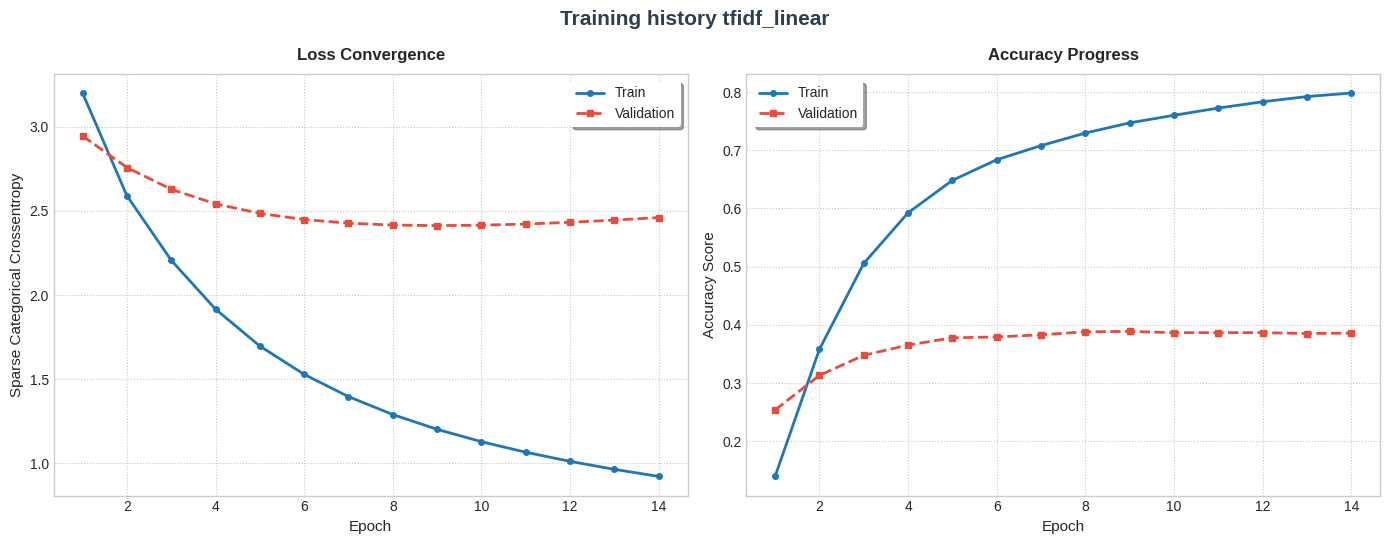

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
{'model': 'tfidf_linear', 'accuracy': 0.3888481291269259, 'micro_f1': 0.3888481291269259, 'macro_f1': 0.3287004773359193}


In [ ]:
save_history_plot(history, 'tfidf_linear', LINEAR_PATH)
evaluate_and_save(model_tfidf_linear, 'tfidf_linear', X_val_tfidf, LINEAR_PATH)
model_tfidf_linear.save(
    os.path.join(LINEAR_PATH, 'checkpoints', f'{date}_tfidf_linear.keras')
)

## Multi-layer perceptron (TF-IDF)

This model represents the next step of our baseline and introduces non-linearity through the ReLU activation to capture complex interactions between TF-IDF features, which are not detectable by a purely linear model.

To avoid overfitting on a high-dimensionality sparse matrix, the architecture is regularized by inserting a fixed **dropout** rate (0.3) after each hidden layer.

We use this architecture to measure the impact and marginal gain of introducing deep dense layers compared to logistic regression, keeping the text representation unchanged.

### Tuning
The optimization dynamically explores the network topology, varying the depth of the architecture (from 1 to 3 hidden layers) and the computational capacity of each layer (128, 256, or 512 units), in order to balance model expressiveness and overfitting risk.

In [ ]:
def build_tfidf_mlp(hp):
    model = keras.Sequential([
        layers.Input(shape=(VOCAB_SIZE,)) # input layer
    ])

    num_layers = hp.Int(
        'num_layers',
        min_value=1,
        max_value=3
    )
    # tuning on number of layers
    for i in range(num_layers):
        # tuning on layer size
        units = hp.Choice(
            f'units_{i}',
            [128, 256, 512]
        )

        dropout = 0.3

        model.add(layers.Dense(
            units,
            activation='relu'
        ))

        model.add(layers.Dropout(dropout)) # dropout layer

    model.add(layers.Dense(NUM_CLASSES, activation='softmax')) # dense layer with softmax

    model.compile(
        optimizer=keras.optimizers.Adam(LR),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [ ]:
tuner_mlp = kt.RandomSearch(
    build_tfidf_mlp,
    objective='val_accuracy',
    max_trials=10,
    directory=TUNER_PATH,
    project_name='tfidf_mlp',
    overwrite=True,
    seed=SEED
)

tuner_mlp.search(
    X_train_tfidf, y_train,
    epochs=EPOCHS,
    validation_data=(X_val_tfidf, y_val),
    batch_size=BATCH_SIZE,
    callbacks=get_callbacks()
)

Trial 10 Complete [00h 00m 07s]
val_accuracy: 0.46294936537742615

Best val_accuracy So Far: 0.4776228964328766
Total elapsed time: 00h 01m 43s


In [ ]:
best_hps = tuner_mlp.get_best_hyperparameters(num_trials=1)[0]
model_tfidf_mlp = tuner_mlp.hypermodel.build(best_hps)

In [ ]:
# model architecture
model_tfidf_mlp.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │       320,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 28)             │         3,612 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 323,740 (1.23 MB)

 Trainable params: 323,740 (1.23 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model_tfidf_mlp.fit(
    X_train_tfidf,
    y_train,
    validation_data=(X_val_tfidf, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=get_callbacks(),
    shuffle=False,
    verbose=1
)

Epoch 1/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.1939 - loss: 3.1376 - val_accuracy: 0.3397 - val_loss: 2.6460
Epoch 2/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4281 - loss: 2.2938 - val_accuracy: 0.4373 - val_loss: 2.2194
Epoch 3/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5487 - loss: 1.7549 - val_accuracy: 0.4629 - val_loss: 2.0700
Epoch 4/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6265 - loss: 1.4140 - val_accuracy: 0.4762 - val_loss: 2.0482
Epoch 5/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6811 - loss: 1.1826 - val_accuracy: 0.4681 - val_loss: 2.0830
Epoch 6/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7272 - loss: 1.0074 - val_accuracy: 0.4593 - val_loss: 2.1284
Epoch 7/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7658 - loss: 0.8674 - val_accuracy: 0.4497 - val_loss: 2.2112
Epoch 8/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7919 - loss: 0.7657 - val_accuracy: 0.4527 - val_loss

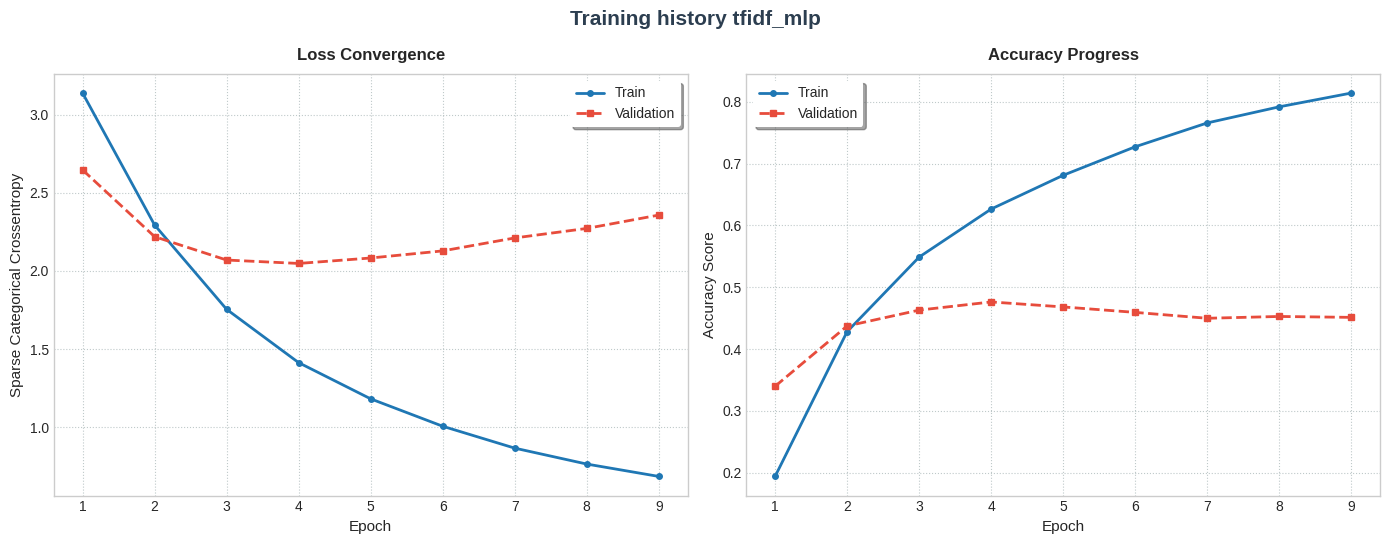

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
{'model': 'tfidf_mlp', 'accuracy': 0.4761555392516508, 'micro_f1': 0.4761555392516508, 'macro_f1': 0.419929347128386}


In [ ]:
save_history_plot(history, 'tfidf_mlp', MLP_PATH)
evaluate_and_save(model_tfidf_mlp, 'tfidf_mlp', X_val_tfidf, MLP_PATH)
model_tfidf_mlp.save(os.path.join(MLP_PATH, 'checkpoints', f'{date}_tfidf_mlp.keras'))

## BiLSTM

With this model we move from static frequentist approaches to sequential Deep Learning models. The BiLSTM processes text as an ordered sequence of tokens, preserving the original syntactic structure of the sentences.

The architecture processes the input bidirectionally (left-to-right and vice versa). This allows capturing both the preceding and following context of each word simultaneously, a crucial factor in a dataset like GoEmotions where the emotional meaning or irony often depends on the combination and order of terms.

We use this architecture to evaluate the effectiveness and the real performance gain resulting from the introduction of local and long-range temporal dependencies, verifying whether the sequential structure of the text offers a more robust signal than the mere presence of keywords.

The text is first converted into dense vectors through an Embedding layer on which the network computes the recurrent state transitions.

In [ ]:
# vectorizer
vectorizer_int = layers.TextVectorization(
    max_tokens=VOCAB_SIZE,
    standardize=None,
    split='whitespace',
    output_mode='int',
    output_sequence_length=SEQ_LEN
)
vectorizer_int.adapt(tf.data.Dataset.from_tensor_slices(X_train).batch(BATCH_SIZE))

X_train_int = vectorizer_int(X_train)
X_val_int = vectorizer_int(X_val)
X_test_int = vectorizer_int(X_test)

In [ ]:
# we save the vectorized data in the path so they can be reused in testing
np.savez_compressed(
    os.path.join(VECTORIZED_PATH, "int_arrays.npz"),
    X_train_int=X_train_int.numpy(),
    X_val_int=X_val_int.numpy(),
    X_test_int=X_test_int.numpy()
)
# we also save the dictionary
with open(os.path.join(VECTORIZED_PATH, "vocab_int.json"), "w") as f:
    json.dump(vectorizer_int.get_vocabulary(), f)

In [ ]:
def build_bilstm(hp):
    model = keras.Sequential([
        layers.Input(shape=(SEQ_LEN,)) # input layer
    ])

    # fixed embedding with masking disabled
    model.add(layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=False
    ))

    # tuning lstm units
    lstm_units = hp.Choice('lstm_units', [64, 128])

    model.add(layers.Bidirectional(
        layers.LSTM(
            lstm_units,
            dropout=0.3,
            activation='tanh',              # activation function for LSTM
            recurrent_activation='sigmoid'  # activation function for the gate
        )
    ))

    # tuning dense units
    dense_units = hp.Choice('dense_units', [32, 64])

    model.add(layers.Dense(dense_units, activation='relu'))
    model.add(layers.Dropout(0.3)) # dropout layer

    model.add(layers.Dense(NUM_CLASSES, activation='softmax', name='output_layer')) # dense layer with softmax

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LR),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

In [ ]:
tuner_bilstm = kt.RandomSearch(
    build_bilstm,
    objective='val_accuracy',
    max_trials=10,
    directory=TUNER_PATH,
    project_name='bilstm',
    overwrite=True,
    seed=SEED
)

tuner_bilstm.search(
    X_train_int, y_train,
    epochs=EPOCHS,
    validation_data=(X_val_int, y_val),
    batch_size=BATCH_SIZE,
    callbacks=get_callbacks()
)

Trial 4 Complete [00h 00m 46s]
val_accuracy: 0.4262655973434448

Best val_accuracy So Far: 0.4262655973434448
Total elapsed time: 00h 03m 40s


In [ ]:
best_hps = tuner_bilstm.get_best_hyperparameters(num_trials=1)[0]
model_bilstm = tuner_bilstm.hypermodel.build(best_hps)

In [ ]:
# model architecture
model_bilstm.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 128, 128)       │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 28)             │         1,820 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 428,892 (1.64 MB)

 Trainable params: 428,892 (1.64 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model_bilstm.fit(
    X_train_int,
    y_train,
    validation_data=(X_val_int, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=get_callbacks(),
    shuffle=False,
    verbose=1
)

Epoch 1/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 8s 56ms/step - accuracy: 0.1525 - loss: 3.1281 - val_accuracy: 0.2018 - val_loss: 2.9523
Epoch 2/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.2294 - loss: 2.8086 - val_accuracy: 0.2810 - val_loss: 2.5899
Epoch 3/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - accuracy: 0.3182 - loss: 2.4813 - val_accuracy: 0.3720 - val_loss: 2.3421
Epoch 4/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - accuracy: 0.3949 - loss: 2.2162 - val_accuracy: 0.3918 - val_loss: 2.2494
Epoch 5/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.4392 - loss: 2.0456 - val_accuracy: 0.4153 - val_loss: 2.2082
Epoch 6/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.4726 - loss: 1.9120 - val_accuracy: 0.4336 - val_loss: 2.2055
Epoch 7/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - accuracy: 0.5008 - loss: 1.8040 - val_accuracy: 0.4255 - val_loss: 2.2235
Epoch 8/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.5313 - loss: 1.6998 - val_accuracy: 0.4248 - v

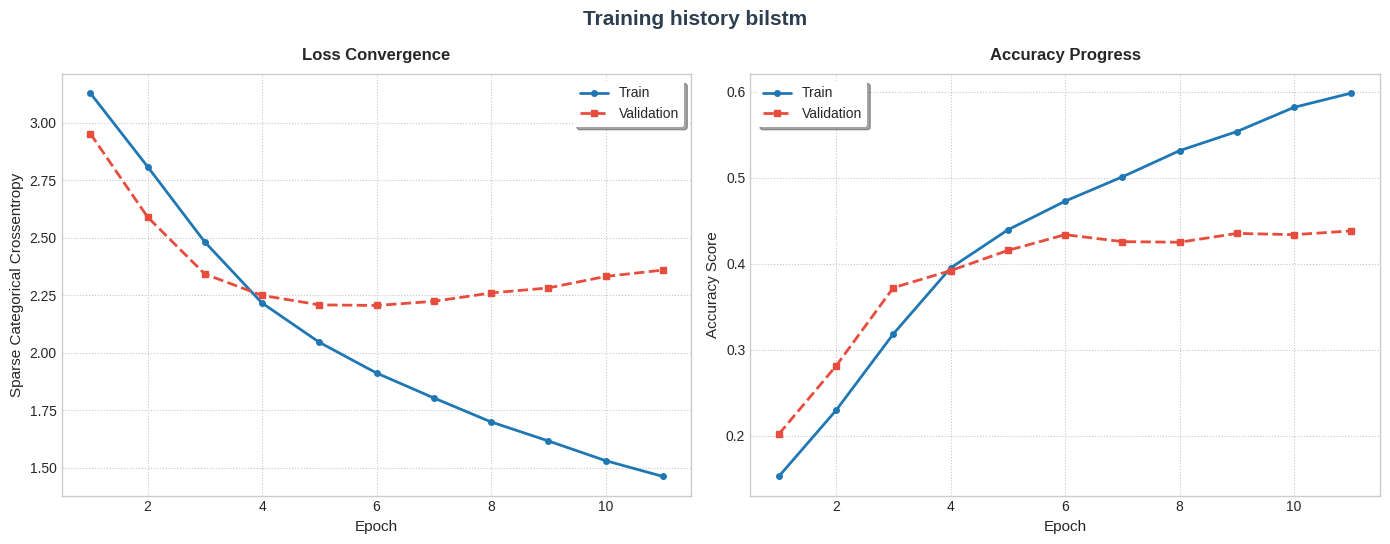

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step
{'model': 'bilstm', 'accuracy': 0.43360234776228906, 'micro_f1': 0.43360234776228906, 'macro_f1': 0.3185323930981699}


In [ ]:
save_history_plot(history, 'bilstm', BILSTM_PATH)
evaluate_and_save(model_bilstm, 'bilstm', X_val_int, BILSTM_PATH)
model_bilstm.save(os.path.join(BILSTM_PATH, 'checkpoints', f'{date}_bilstm.keras'))

## Transformer from scratch (Encoder-only)

The final level of experimentation introduces the Transformer architecture, limited to the Encoder component only.

Unlike classic sequential models such as LSTMs, the Transformer discards temporal recursion in favor of parallel Self-Attention mechanisms, allowing it to analyze semantic relationships between words at any distance within the comment in a single computational pass.

The architecture was developed entirely custom and includes:

- A Positional Embedding block: to add information about token order

- Encoder Block structures: implementing the modern Pre-Layer Normalization pattern and residual connections, ensuring greater gradient stability during optimization

The custom layers `PositionalEmbedding` and `EncoderBlock` are defined in `experiments/transformer/transformer_layers.py` and imported below. This keeps the training and testing notebooks aligned on a single source of truth, avoiding duplicated `@register_keras_serializable` registrations and ensuring that the `.keras` checkpoint saved here can be reloaded correctly in `03_testing.ipynb`.

With this model we want to verify whether the volume of data extracted from GoEmotions is sufficient to make a complex architecture converge without the biases of pre-trained models, comparing the effectiveness of the attention mechanism against the baselines and recurrent networks.

### Tuning
The tuning explores the global expressive capacity of the Transformer by acting on:

- vector dimensionality (embed_dim)
- number of attention heads (num_heads)
- depth of the sequential blocks (num_layers)
- internal Transformer dropout (trans_dropout)
- final classifier dropout (class_dropout)

In [ ]:
"""Custom layers (PositionalEmbedding, EncoderBlock) live in
experiments/transformer/transformer_layers.py so that both this
notebook and 03_testing.ipynb load exactly the same registered classes."""

if TRANSFORMER_PATH not in sys.path:
    sys.path.append(TRANSFORMER_PATH)
from transformer_layers import PositionalEmbedding, EncoderBlock

In [ ]:
def build_transformer_scratch(hp):
    # tuning vector dimensionality
    embed_dim = hp.Choice("embed_dim",          [64, 128, 256])
    # tuning number of attention heads
    num_heads = hp.Choice("num_heads",          [4, 8])
    num_layers = hp.Int("num_layers",           min_value=1, max_value=4)
    trans_drop = hp.Float("trans_dropout",      min_value=0.1, max_value=0.3, step=0.1)
    class_drop = hp.Float("class_dropout",      min_value=0.1, max_value=0.3, step=0.1)

    ff_dim = embed_dim * 4  # standard proportion, not worth tuning

    # architecture
    inputs = keras.Input(shape=(SEQ_LEN,))
    x = PositionalEmbedding(VOCAB_SIZE, embed_dim, SEQ_LEN)(inputs) # X + PE

    for _ in range(num_layers):
        x = EncoderBlock(embed_dim, num_heads, ff_dim, trans_drop)(x)

    x = layers.GlobalAveragePooling1D()(x)   # aggregates the tokens, respects the mask
    x = layers.Dropout(class_drop)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.AdamW(learning_rate=LR, weight_decay=0.01),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

In [ ]:
tuner_transformer = kt.RandomSearch(
    build_transformer_scratch,
    objective='val_accuracy',
    max_trials=10,
    directory=TUNER_PATH,
    project_name='transformer_scratch',
    overwrite=True,
    seed=SEED
)

# start the search
tuner_transformer.search(
    X_train_int, y_train,
    epochs=EPOCHS,
    validation_data=(X_val_int, y_val),
    batch_size=BATCH_SIZE,
    callbacks=get_callbacks()
)

Trial 10 Complete [00h 00m 25s]
val_accuracy: 0.40425533056259155

Best val_accuracy So Far: 0.45781365036964417
Total elapsed time: 00h 11m 06s


In [ ]:
# get the optimal hyperparameters
best_hps = tuner_transformer.get_best_hyperparameters(num_trials=1)[0]

# build the model with the optimal hyperparameters
model_transformer = tuner_transformer.hypermodel.build(best_hps)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'encoder_block_1' (of type EncoderBlock) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


In [ ]:
model_transformer.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ positional_embedding_1          │ (None, 128, 64)        │       168,192 │
│ (PositionalEmbedding)           │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_block_1 (EncoderBlock)  │ (None, 128, 64)        │        49,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_block_2 (EncoderBlock)  │ (None, 128, 64)        │        49,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_block_3 (EncoderBlock)  │ (None, 128, 64)        │        49,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 28)             │         1,820 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 319,964 (1.22 MB)

 Trainable params: 319,964 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 15s 59ms/step - accuracy: 0.1779 - loss: 3.0639 - val_accuracy: 0.3390 - val_loss: 2.4973
Epoch 2/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.3898 - loss: 2.3065 - val_accuracy: 0.4233 - val_loss: 2.1565
Epoch 3/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - accuracy: 0.4938 - loss: 1.8890 - val_accuracy: 0.4285 - val_loss: 2.2375
Epoch 4/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - accuracy: 0.5706 - loss: 1.6060 - val_accuracy: 0.4116 - val_loss: 2.3369
Epoch 5/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.6305 - loss: 1.3922 - val_accuracy: 0.4241 - val_loss: 2.4775
Epoch 6/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - accuracy: 0.6643 - loss: 1.2555 - val_accuracy: 0.4109 - val_loss: 2.6841
Epoch 7/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - accuracy: 0.6940 - loss: 1.1543 - val_accuracy: 0.3940 - val_loss: 2.8599


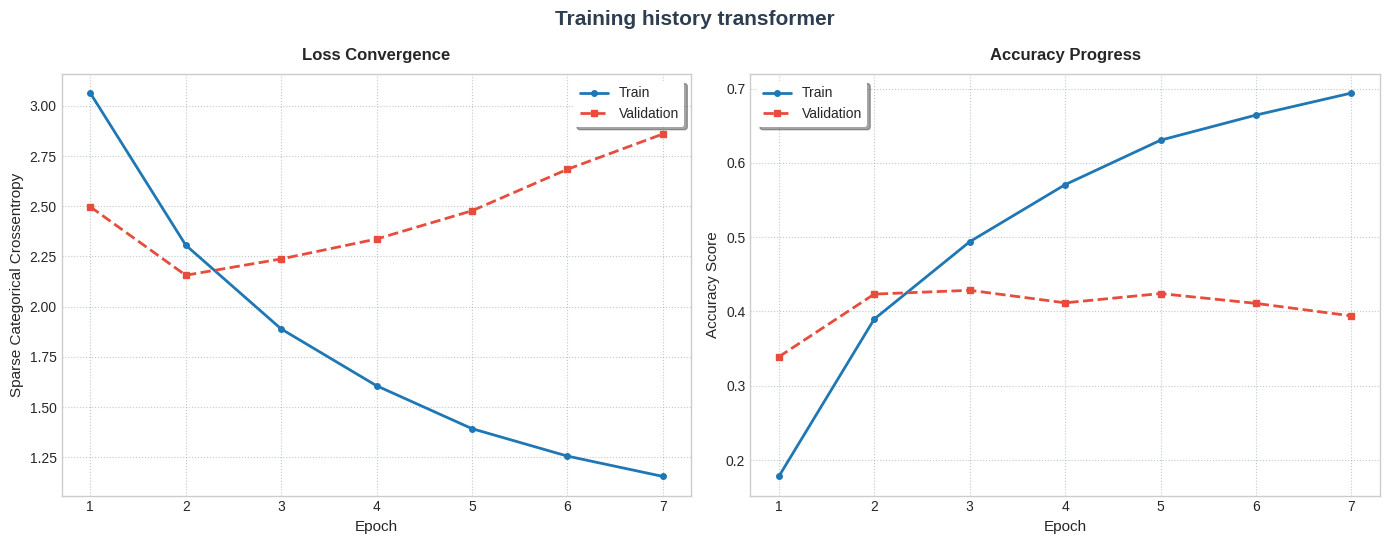

/usr/local/lib/python3.12/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'encoder_block_1' (of type EncoderBlock) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step
{'model': 'transformer', 'accuracy': 0.42333088774761557, 'micro_f1': 0.42333088774761557, 'macro_f1': 0.3093870644069252}


In [ ]:
history = model_transformer.fit(
    X_train_int,
    y_train,
    validation_data=(X_val_int, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=get_callbacks(),
    shuffle=False,
    verbose=1
)

save_history_plot(history, 'transformer', TRANSFORMER_PATH)
evaluate_and_save(model_transformer, 'transformer', X_val_int, TRANSFORMER_PATH)
model_transformer.save(os.path.join(TRANSFORMER_PATH, 'checkpoints', f'{date}_transformer.keras'))

## Final comparison on validation

In this section, the results obtained from the four tested architectures on the validation set are aggregated and analyzed. The comparison allows drawing fundamental conclusions about the effectiveness of the different text representations.

In [ ]:
def plot_and_save_metrics(metrics_list, current_date, output_path):
    """
    Prints the model metrics, exports the csv report and generates a comparative bar chart (Macro F1 vs Micro F1).
    """
    # create df, sort and export csv
    metrics_df = pd.DataFrame(metrics_list)
    metrics_df = metrics_df.sort_values(['model'])

    print(f"Metrics report:")
    display(metrics_df)

    # visual style configuration
    plt.style.use('seaborn-v0_8-whitegrid')
    fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

    # consistent color palette to visually identify the four architectures
    palette = ['#C44E52', '#4C72B0', '#2ecc71', '#8172B2']

    # clean formatting of model names for the x-axis (removes underscores)
    model_labels = [str(m).replace('_', ' ').title() for m in metrics_df['model']]

    # macro f1 subplot
    bars1 = axes[0].bar(model_labels, metrics_df['macro_f1'], color=palette, edgecolor='#2c3e50', alpha=1, width=0.55)
    axes[0].set_title('Macro F1 Score (Class Fairness)', fontsize=13, fontweight='semibold', pad=12)
    axes[0].set_ylabel('Score', fontsize=11)

    # micro f1 subplot
    bars2 = axes[1].bar(model_labels, metrics_df['micro_f1'], color=palette, edgecolor='#2c3e50', alpha=1, width=0.55)
    axes[1].set_title('Micro F1 Score (Global Accuracy)', fontsize=13, fontweight='semibold', pad=12)

    fig.suptitle('Validation metrics comparison', fontsize=16, fontweight='bold', y=1.02, color='#2c3e50')

    for ax, bars in zip(axes, [bars1, bars2]):
        ax.set_ylim(0, 1.0)
        ax.set_xlabel('Architecture', fontsize=11, labelpad=10)
        ax.grid(True, linestyle='--', alpha=0.5, axis='x')

        # slanted rotation to avoid overlapping of long names
        ax.set_xticklabels(model_labels, rotation=0, ha='center', fontsize=10)
        ax.tick_params(axis='y', labelsize=10)

        # automatic insertion of text labels above the individual bars
        for bar in bars:
            height = bar.get_height()
            ax.annotate(f'{height:.3f}',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 4),  # 4 points of vertical offset
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=10, fontweight='bold', color='#2c3e50')

    # compact the layout before saving
    plt.tight_layout()

    png_filename = f'{current_date}_validation_metrics_comparison.png'
    plt.savefig(os.path.join(output_path, png_filename), dpi=300, bbox_inches='tight')

    plt.show()

Report metriche:


,model,accuracy,micro_f1,macro_f1
2,bilstm,0.433602,0.433602,0.318532
0,tfidf_linear,0.388848,0.388848,0.328700
1,tfidf_mlp,0.476156,0.476156,0.419929
3,transformer,0.423331,0.423331,0.309387


/tmp/ipykernel_1519/2088109001.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(model_labels, rotation=0, ha='center', fontsize=10)
/tmp/ipykernel_1519/2088109001.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(model_labels, rotation=0, ha='center', fontsize=10)


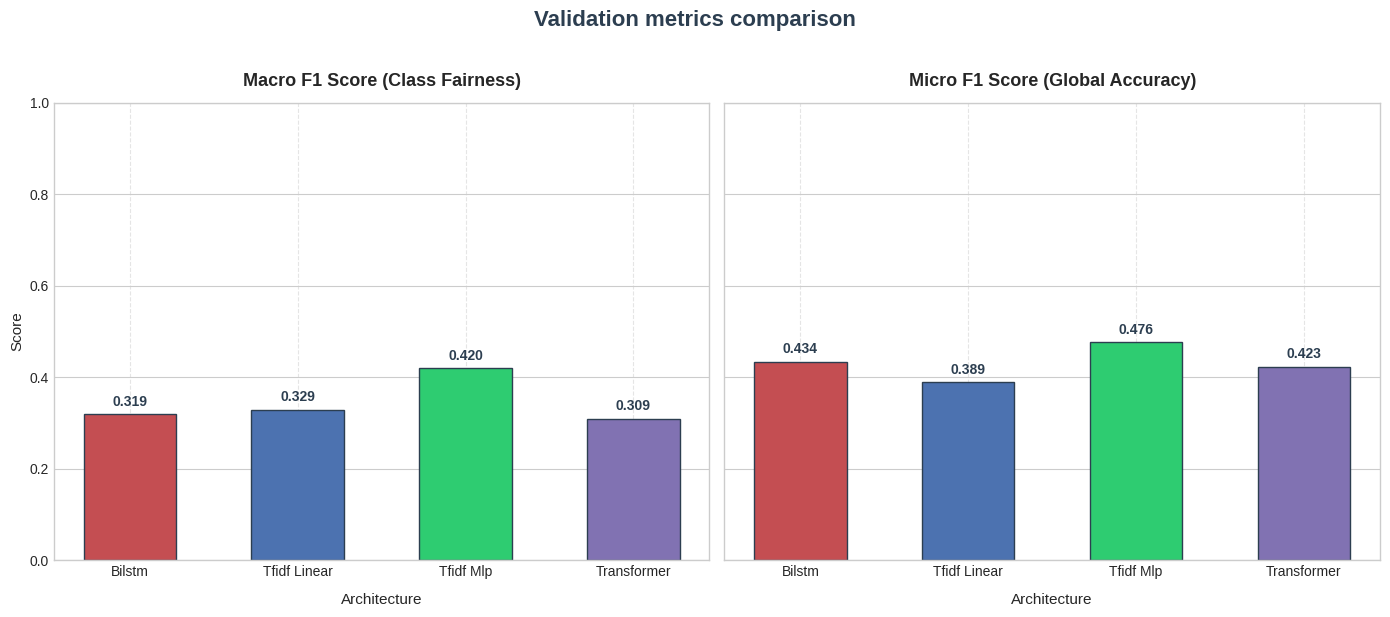

In [ ]:
plot_and_save_metrics(all_metrics, date, COMPARISON_PATH)

## Results analysis and model comparison

### MLP

The most evident and interesting finding is the clear superiority of the TF-IDF + MLP combination, which achieves the best performance both in terms of global accuracy (Micro-F1) and, above all, Macro-F1.

This clear gap in Macro F1 indicates that the MLP is the architecture that best generalizes on the rarest or most imbalanced classes of the dataset during validation. The introduction of non-linearity combined with a robust representation based on keyword frequencies proved to be decidedly more effective than sequential or attention-based modeling trained from scratch.

### BiLSTM

The BiLSTM ranks in the intermediate range for global accuracy on the validation set, but suffers a significant drop in Macro F1, falling to values similar to those of the linear baseline.

This behavior demonstrates that, although the bidirectional sequential structure manages to capture the local dynamics of sentences well for majority classes, it struggles enormously to extract robust patterns for underrepresented emotions. The main cause lies in the limited size of the filtered dataset, which makes training a recurrent architecture from scratch on low-support classes complex and under-optimized.

### Transformer

The Transformer reaches global accuracy levels close to those of the BiLSTM, but records the lowest Macro F1 among all architectures tested in validation.

Transformers do not assume that nearby tokens are correlated, nor do they benefit from the statistical selectivity of TF-IDF counts. Consequently, they require massive volumes of data to converge efficiently. Training a Transformer from scratch on a reduced single-label subset drastically limits its ability to generalize on the long tail of minority classes.

### Logistic Regression

Logistic Regression closes the ranking in terms of global accuracy, but shows a surprisingly stable Macro F1, which directly rivals that of the BiLSTM and surpasses that of the Transformer.

This dynamic confirms that for some specific emotions, the mere presence of a strong and unambiguous emotional token proves to be a more reliable and less overfitting-prone signal than a complex but under-optimized interpretation.

### Conclusions

The experiment on the validation set highlights how, for this specific data setup, architectural complexity is not synonymous with immediate success.

Approaches based on stable frequentist features supported by deep non-linear layers (MLP) offer the best computational and predictive trade-off, protecting the model from noise and serving as a solid starting point for subsequent disaggregated and Explainable AI analyses.